# Setup

Making sure the right python version is being used, because Python 3.7 or above is required for this project:

In [4]:
import sys

assert sys.version_info >= (3, 7)

Making sure the right Scikit-Learn version is being used, because Scikit-Learn 1.0.1 or above is required for this project:

In [5]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

# Getting the Data for the house price file

Welcome to Assignment 1 for Introduction to Atrifical Intelligence Module. My task is to analyse the sales data of a large US based estate and improve their business operations using machine learning. My task includes cleaning up the given dataset, visualising critical information, and developing solutions using techniques learned from this module.

## Downloading the Data

In [6]:
import pandas as pd
houseprice_raw = pd.read_csv('As1datasets/houseprice.csv') #reading the dataset
original_df2 = houseprice_raw.copy() #keeping a copy of the original dataset

## Taking a Quick Look at the Data Structure

In [7]:
houseprice_raw.head()

,Price,Sqr Ft,Longitude,Latitude,Lot Size,Beds,Bath,Year Built,Last Sold Year,Last Sold For,Address,City,State,Zipcode,Address Full
0,"$895,900","3,447 sqft",-112.081985,33.560055,"7,895 sqft",4.0,4.5,2019.0,NaN,NaN,"630 W Echo Ln Phoenix, AZ 85021",Phoenix,AZ,85021.0,"630 W Echo Ln, Phoenix, AZ 85021"
1,"$247,000","1,767 sqft",-96.676250,32.829227,"7,877 sqft",3.0,2.0,1954.0,NaN,NaN,"2367 Highwood Dr Dallas, TX 75228",Dallas,TX,75228.0,"2367 Highwood Dr, Dallas, TX 75228"
2,"$44,900","1,232 sqft",-78.825190,42.913000,"3,510 sqft",3.0,1.0,1900.0,NaN,NaN,"30 Hurlock Ave Buffalo, NY 14211",Buffalo,NY,14211.0,"30 Hurlock Ave, Buffalo, NY 14211"
3,"$959,000","1,417 sqft",-73.860170,40.722960,"2,598 sqft",3.0,2.0,1939.0,2009.0,"$532,000","6416 Alderton St Flushing, NY 11374",Flushing,NY,11374.0,"6416 Alderton St, Flushing, NY 11374"
4,"$83,500",440 sqft,-80.206314,25.937965,NaN,NaN,1.0,1971.0,2007.0,"$52,000","251 NW 177th St #A-123 Miami Gardens, FL 33169",Miami Gardens,FL,33169.0,"251 NW 177th St #A-123, Miami Gardens, FL 33169"


In [8]:
houseprice_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30006 entries, 0 to 30005
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Price           30006 non-null  object 
 1   Sqr Ft          27786 non-null  object 
 2   Longitude       30006 non-null  float64
 3   Latitude        30006 non-null  float64
 4   Lot Size        25490 non-null  object 
 5   Beds            27420 non-null  float64
 6   Bath            27496 non-null  float64
 7   Year Built      26258 non-null  float64
 8   Last Sold Year  14213 non-null  float64
 9   Last Sold For   14213 non-null  object 
 10  Address         30006 non-null  object 
 11  City            30006 non-null  object 
 12  State           30006 non-null  object 
 13  Zipcode         30003 non-null  float64
 14  Address Full    30006 non-null  object 
dtypes: float64(7), object(8)
memory usage: 3.4+ MB


In [9]:
houseprice_raw["Last Sold For"].value_counts()

Last Sold For
$125,000      88
$175,000      82
$250,000      81
$150,000      81
$130,000      77
              ..
$53,947        1
$247,272       1
$193,697       1
$606,600       1
$5,500,000     1
Name: count, Length: 3868, dtype: int64

In [10]:
houseprice_raw.describe()

,Longitude,Latitude,Beds,Bath,Year Built,Last Sold Year,Zipcode
count,30006.000000,30006.000000,27420.000000,27496.000000,26258.000000,14213.000000,30003.000000
mean,-95.167341,36.158007,3.288658,2.578688,1973.140224,2011.110673,59349.268440
std,15.454027,5.500075,1.472238,1.448891,34.512400,6.596002,27206.130444
min,-150.047160,25.550295,1.000000,0.750000,1800.000000,1987.000000,2108.000000
25%,-106.742751,32.747084,3.000000,2.000000,1950.000000,2006.000000,33137.000000
50%,-93.390977,36.016481,3.000000,2.000000,1978.000000,2013.000000,68124.000000
75%,-81.638904,40.017658,4.000000,3.000000,2004.000000,2017.000000,85016.000000
max,-70.997740,61.442024,65.000000,98.000000,2019.000000,2019.000000,99587.000000


The following cell creates the `images/end_to_end_project` folder (if it doesn't already exist), and it defines the `save_fig()` function to save the figures in high-res for the book.

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

IMAGES_PATH = Path() / "As1images" / "end_to_end_project" #appends As1images to the folder, and appends end_to_end_project as its subfolder
IMAGES_PATH.mkdir(parents=True, exist_ok=True) #creates the folder if it does not already exist

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300): #creating a function to save the figures
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout: #if it has a tight layout then do the follwoing
        plt.tight_layout() #calling the tight_layout function
    plt.savefig(path, format=fig_extension, dpi=resolution) #saving the figure in the images folder

The following cell contains code for setting the the default font sizes

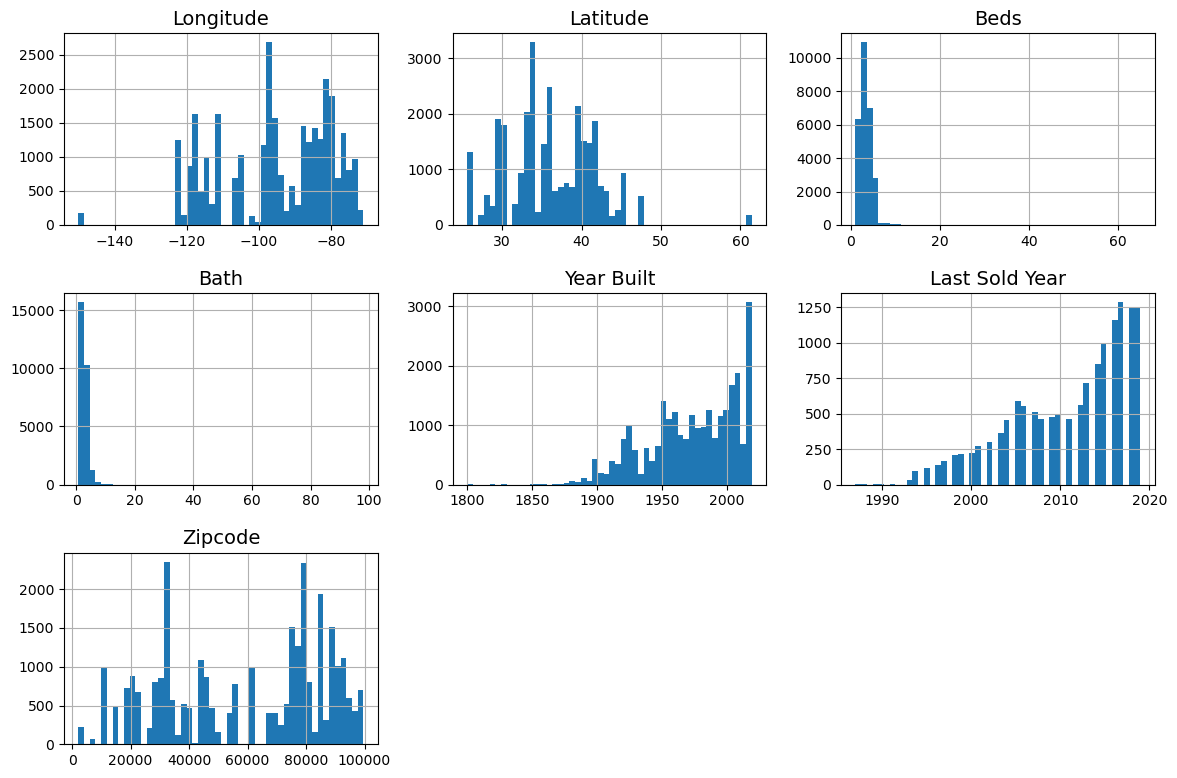

In [12]:
#code for the default font sizes
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

houseprice_raw.hist(bins=50, figsize=(12, 8))
save_fig("attribute_histogram_plots") #giving it a "fig_id = attribute_histogram_plots", and saving the figure in the images folder
plt.show()

I started by spending some time to explore and the date, and then visulaize it. These were the first steps I have done.

# Data Cleaning

In [ ]:
import pandas as pd
from sklearn.impute import SimpleImputer

def clean_housing_data(houseprice_raw):
    #creating a copy to avoid changing the original raw data
    df_clean = houseprice_raw.copy()
    
    #dropping duplicates
    df_clean = df_clean.drop_duplicates()
    
    #dropping rows where Price is missing
    df_clean = df_clean.dropna(subset=['Price'])

    if 'Lot Size' in df_clean.columns:
        #detecting which rows contain acre
        is_acres = df_clean['Lot Size'].astype(str).str.contains('acre', case=False, na=False)
        
        #removing commas and extracting just the numbers/decimals
        df_clean['Lot Size'] = df_clean['Lot Size'].astype(str).str.replace(r'[a-zA-Z, ]', '', regex=True).str.strip()
        df_clean['Lot Size'] = pd.to_numeric(df_clean['Lot Size'], errors='coerce')
        
        #multiplying ONLY the rows flagged as acres by 43,560
        df_clean.loc[is_acres, 'Lot Size'] *= 43560
    
    #cleaning columns by Removing $, commas, and text in the following columns: Price, Last Sold For, Sqr Ft, Lot Size
    cols_to_clean = ['Price', 'Last Sold For', 'Sqr Ft', 'Lot Size']
    for col in cols_to_clean:
        if col in df_clean.columns:
            # Removing letters, commas, and symbols
            df_clean[col] = df_clean[col].astype(str).str.replace(r'[a-zA-Z,$\+ ]', '', regex=True).str.strip()
            df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

    #filling missing Sqr Ft based on the median of the City
    if 'Sqr Ft' in df_clean.columns and 'City' in df_clean.columns:
        df_clean['Sqr Ft'] = df_clean.groupby('City')['Sqr Ft'].transform(
            lambda x: x.fillna(x.median())
        )
        #and if there are still rows that have a missing Sqr Ft(for example, a city had no Sqr Ft data at all), then we would fill the Sqr Ft of that city with a global median
        df_clean['Sqr Ft'] = df_clean['Sqr Ft'].fillna(df_clean['Sqr Ft'].median())
        
    #removing Outliers using the IQR Method for Price. startign first by calculating the upper and lower Quartiles
    Q1 = df_clean['Price'].quantile(0.25)
    Q3 = df_clean['Price'].quantile(0.75)
    #calucating the Interquartile range
    IQR = Q3 - Q1
    
    #defining the bounds according to the standard statistical threshold (1.5 * IQR is the standard statistical threshold)
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    #keeping only the rows that are within the bounds
    df_clean = df_clean[(df_clean['Price'] >= lower_bound) & (df_clean['Price'] <= upper_bound)]
    
    #grouping the columns that has continuous numerical data together because it makes sense to get their average for example size, and for example number of rooms)
    numeric_columns = ["Sqr Ft", "Lot Size", "Beds", "Bath", "Year Built"]

    #gruping the columns that are Categorical and has discrete data together, because I do not need to get the average of a zipcode, because it wouldn't make sense
    categorical_columns = ["Last Sold Year", "Zipcode", "Last Sold For"]

    #filling missing values using SimpleImputer, and using 'mean' for continuous numbers and 'most_frequent' for categorical/discrete data, so separating the columns into two lists based on their data type and how to handle them
    #so for numerical columns, filling missing values (NaNs) with the mathematical average (mean) of that column
    numeric_imputer = SimpleImputer(strategy="mean")
    #and for categorical columns, filling missing values with the most common value (mode) found in that column
    categorical_imputer = SimpleImputer(strategy="most_frequent")

    #calculating the mean for each numerical column and instantly replacing the missing values in the dataframe
    df_clean[numeric_columns] = numeric_imputer.fit_transform(df_clean[numeric_columns])

    #calculating the most frequent value for each categorical column and instantly replacing the missing values
    df_clean[categorical_columns] = categorical_imputer.fit_transform(df_clean[categorical_columns])
    
    return df_clean

In [14]:
#running the houseprice dataset cleaning function, and storing the cleaned data in the variable cleaned_df
cleaned_df = clean_housing_data(houseprice_raw)

In [15]:
#exporting the cleaned data to a new CSV file without the index column
cleaned_df.to_csv("my_cleaned_dataset.csv", index=False)

print(f"Data cleaned successfully! Remaining rows: {len(cleaned_df)}")

Data cleaned successfully! Remaining rows: 27136


After cleanig the houseprice dataset using a cleaning function, I want to see the correlation between the columns of the dataset through a heatmap